# Track B: Recommender System - Spotify Tracks Dataset

**Course**: MSc Artificial Intelligence - Machine Learning (Unit 11)
**Dataset**: [Spotify Selection Dataset (Kaggle - Maharshi Pandya)](https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset)

## Project Objective
This notebook implements a Content-Based Recommender System (CBRS) and Audio Feature Preference Ranker comparing **Traditional Machine Learning** and **Deep Learning** models using the Spotify Selection Dataset.


## 1. Environment Setup & Data Loading

To download the dataset automatically via Kaggle API:
1. Obtain your Kaggle API key (`kaggle.json`) from https://www.kaggle.com/settings/api.
2. Place your credentials in a `.env` file or standard Kaggle configuration path.
3. Activate your virtual environment and install requirements (`pip install -r requirements.txt`).

In [41]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
import kaggle
import missingno 

load_dotenv()

True

In [42]:
# Load Kaggle Spotify Selection Dataset
datasets_path = Path("dataset")
csv_file = datasets_path / "dataset.csv"

if not csv_file.exists():
    print("Downloading Spotify Selection Dataset from Kaggle...")
    kaggle.api.dataset_download_files(
        "maharshipandya/-spotify-tracks-dataset", path=datasets_path, unzip=True
    )

df_tracks = pd.read_csv(csv_file)

# Drop index column if present
if "Unnamed: 0" in df_tracks.columns:
    df_tracks = df_tracks.drop(columns=["Unnamed: 0"])

print(f"Dataset successfully loaded. Total rows: {len(df_tracks):,}, Total columns: {len(df_tracks.columns)}")

Dataset successfully loaded. Total rows: 114,000, Total columns: 20


<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  str    
 1   artists           113999 non-null  str    
 2   album_name        113999 non-null  str    
 3   track_name        113999 non-null  str    
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           114000 non-nu

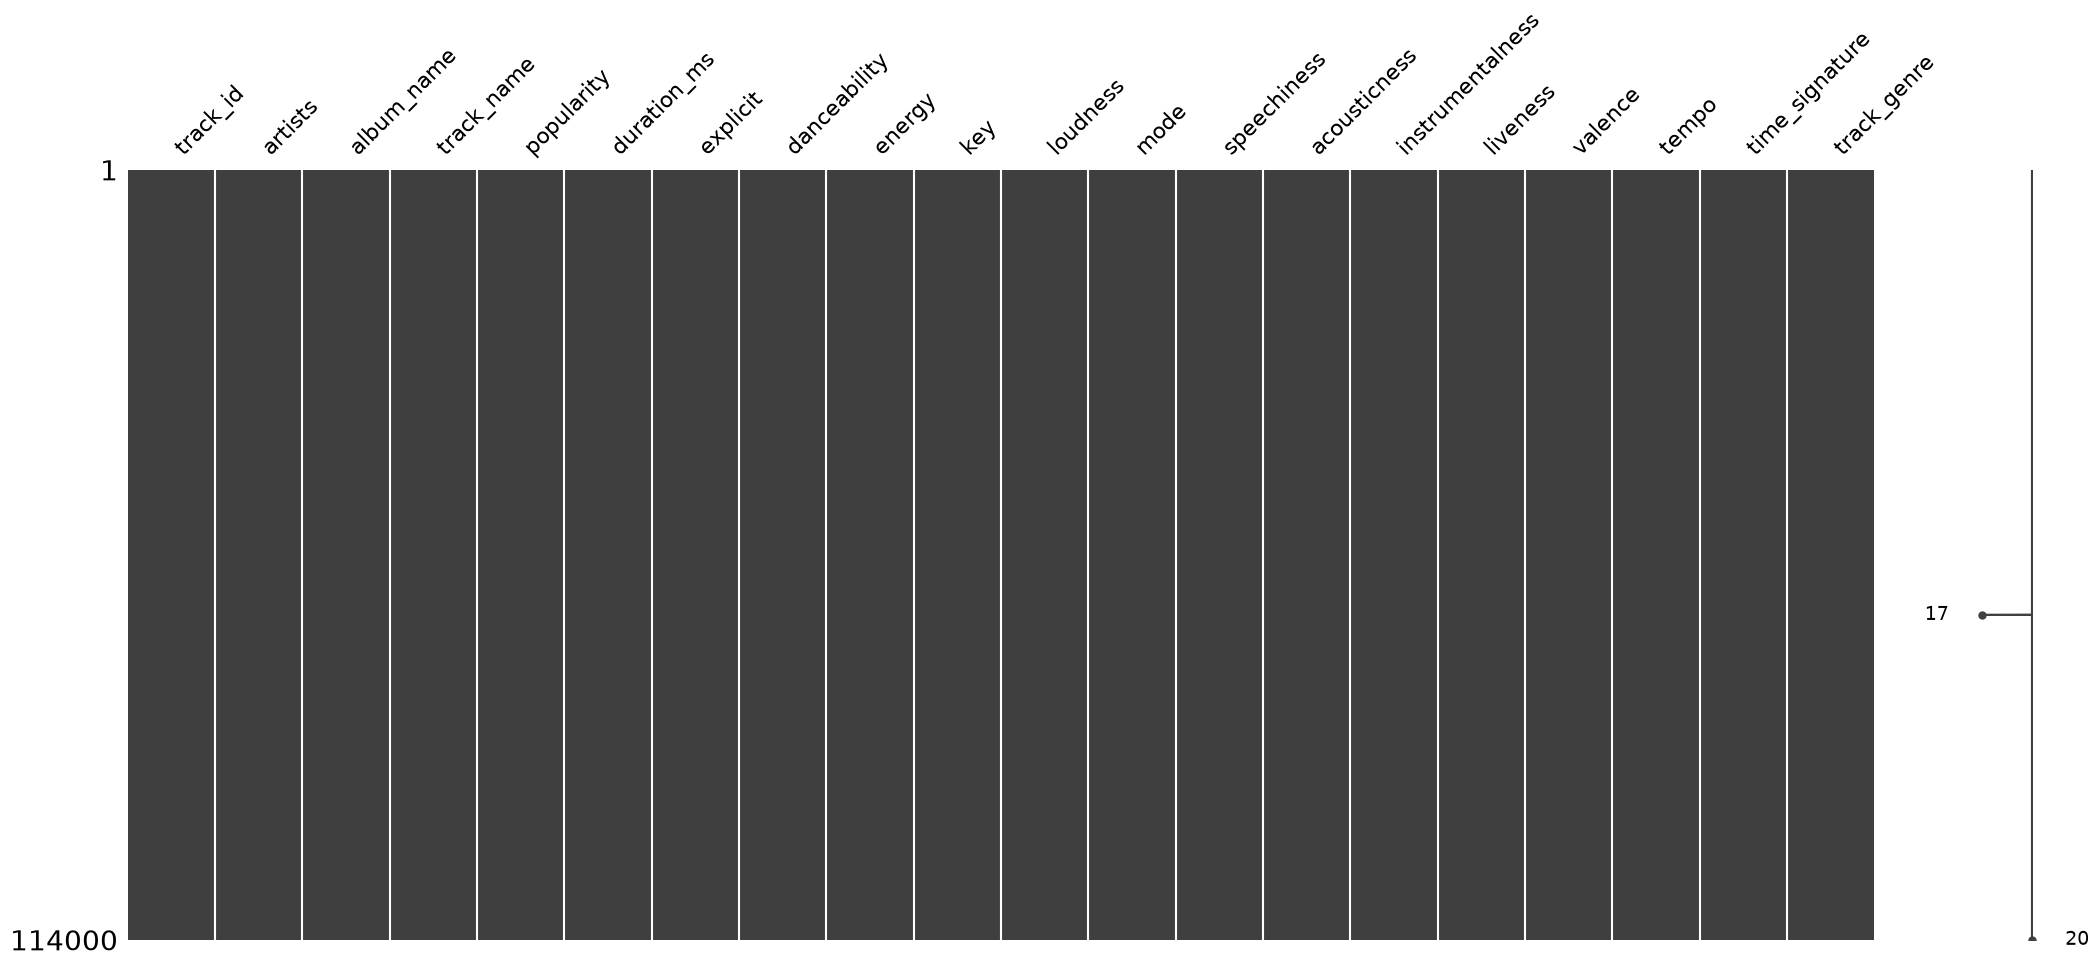

In [43]:
df_tracks.info() # Initial Inspection
missingno.matrix(df_tracks)
df_tracks.describe()

# look for duplicates
all_tracks = len(df_tracks) # count total
unique_tracks = len(df_tracks[['artists', 'track_name', 'album_name', 'tempo']].drop_duplicates()) # count unique combinations for the same artist and track name
unique_tracks_w_genre = len(df_tracks[['artists', 'track_name', 'album_name', 'tempo', 'track_genre']].drop_duplicates())
print(f"Total tracks: {all_tracks} - Unique tracks: {unique_tracks} - Unique tracks by genre: {unique_tracks_w_genre}")

## Notes:
- No null values in any columns.
- Found data with no 0 values for `danceability`, `energy`, `key`, `mode`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`, or `time_signature`.
- Found total 89536 unique tracks out of 114000: songs appear repeated for multiple genre.

## TO-DO: 
- Analyse outliers and zero-values (possible noise).
- Sample data to understand it.
- Combine genres for multi-genre tracks: 89536 out of 113269 have just one genre, the rest have multiple, and removing any secondary genres would be losing information.

In [44]:
df_tracks.head() # Preview first 5 rows

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [45]:
df_genres = df_tracks.groupby("track_id")["track_genre"].apply(list).reset_index()
df_genres.rename(columns={"track_genre": "genres_list"}, inplace=True)
df_unique = df_tracks.drop_duplicates(subset=["track_id"]).copy()
df_clean = df_unique.merge(df_genres, on="track_id", how="left")
df_clean = df_clean.drop(columns=["track_genre"])
display(df_clean)

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,genres_list
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,"[acoustic, j-pop, singer-songwriter, songwriter]"
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,"[acoustic, chill]"
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,[acoustic]
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,[acoustic]
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,[acoustic]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89736,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,5,-16.393,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,[world-music]
89737,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,0,-18.318,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,[world-music]
89738,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,0,-10.895,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,[world-music]
89739,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.5060,7,-10.889,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,[world-music]


In [46]:
# feature engineering over strings
df_engineered = df_clean.copy()
df_engineered["artists_list"] = df_clean["artists"].fillna("").apply(lambda x: x.split(";"))
df_engineered = df_engineered.drop(columns=["artists"], errors="ignore")
df_engineered["is_acoustic_version"] = df_engineered["track_name"].str.contains("acoustic", case=False, na=False) | \
                                  df_engineered["album_name"].str.contains("acoustic", case=False, na=False)
df_engineered["is_remix_version"] = df_engineered["track_name"].str.contains("remix", case=False, na=False) | \
                                  df_engineered["album_name"].str.contains("remix", case=False, na=False)

num_acoustic_text = df_engineered["is_acoustic_version"].sum()
print(f"Tracks titled as acoustic: {num_acoustic_text:,}")

print("\nMathematical comparison of tag vs acousticness")
display(df_engineered.groupby("is_acoustic_version")["acousticness"].mean().reset_index())

display(df_engineered[df_engineered["is_acoustic_version"] == True][["track_name", "artists_list", "is_acoustic_version", "acousticness"]].sort_values(by="acousticness").head())

Tracks titled as acoustic: 296

Mathematical comparison of tag vs acousticness


,is_acoustic_version,acousticness
0,False,0.327033
1,True,0.707844


,track_name,artists_list,is_acoustic_version,acousticness
39829,Save Me - Acoustic; Live from Kansas City,[Shinedown],True,0.000777
42004,You Are My Religion,[Firehouse],True,0.007040
37370,Saturnine - Semi-Acoustic Live version,[The Gathering],True,0.008460
50050,Forget to Remember - Acoustic,[Mudvayne],True,0.010100
39880,The Crow & the Butterfly - Acoustic; Live from...,[Shinedown],True,0.016500


In [47]:
# According to Spotify API key 0 is C (which is correct); however, `tempo == 0` bpm or `time_signature == 0` is pure white noise silence, or corrupt.
df_engineered_1 = df_engineered.copy()
corrupted_tracks = df_engineered[df_engineered_1["tempo"] == 0]
print(f"Tracks with tempo = 0: {len(corrupted_tracks)}")

if len(corrupted_tracks) > 0:
    print("Tempo = 0 tracks sample:")
    display(corrupted_tracks[["track_name", "genres_list", "tempo", "danceability", "energy"]].head())

df_engineered_1 = df_engineered_1[df_engineered_1["tempo"] > 0]
print(f"Final dataset contains: {len(df_engineered_1):,} rows.")

Tracks with tempo = 0: 157
Tempo = 0 tracks sample:


,track_name,genres_list,tempo,danceability,energy
3536,The Departure,[ambient],0.0,0.0,0.03620
3784,The End of Childhood (feat. Jack Liebeck),[ambient],0.0,0.0,0.04450
4068,Ferme Les Yeux,[ambient],0.0,0.0,0.03230
40502,Campomoro,[guitar],0.0,0.0,0.00108
40552,Ritornello,[guitar],0.0,0.0,0.00129


Final dataset contains: 89,584 rows.


In [48]:
# apply mode to time_signature == 0 for ML/DL models (categorical value)
df_engineered_2 = df_engineered_1.copy()
mode_time_signature = df_engineered_2["time_signature"].mode()[0]
print(f"time_signature mode is: {mode_time_signature}")
num_zeros_ts = len(df_engineered_2[df_engineered_2["time_signature"] == 0])
print(f"Replacing time_signature = 0 with the mode to {num_zeros_ts} tracks...")
df_engineered_2["time_signature"] = df_engineered_2["time_signature"].replace(0, mode_time_signature)
print("Verify imputation:")
print(df_engineered_2["time_signature"].value_counts())

time_signature mode is: 4
Replacing time_signature = 0 with the mode to 5 tracks...
Verify imputation:
time_signature
4    79549
3     7604
5     1585
1      846
Name: count, dtype: int64


In [50]:
display(df_engineered_2)

,track_id,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,...,acousticness,instrumentalness,liveness,valence,tempo,time_signature,genres_list,artists_list,is_acoustic_version,is_remix_version
0,5SuOikwiRyPMVoIQDJUgSV,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,...,0.0322,0.000001,0.3580,0.7150,87.917,4,"[acoustic, j-pop, singer-songwriter, songwriter]",[Gen Hoshino],False,False
1,4qPNDBW1i3p13qLCt0Ki3A,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,...,0.9240,0.000006,0.1010,0.2670,77.489,4,"[acoustic, chill]",[Ben Woodward],True,False
2,1iJBSr7s7jYXzM8EGcbK5b,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,...,0.2100,0.000000,0.1170,0.1200,76.332,4,[acoustic],"[Ingrid Michaelson, ZAYN]",False,False
3,6lfxq3CG4xtTiEg7opyCyx,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,...,0.9050,0.000071,0.1320,0.1430,181.740,3,[acoustic],[Kina Grannis],False,False
4,5vjLSffimiIP26QG5WcN2K,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,...,0.4690,0.000000,0.0829,0.1670,119.949,4,[acoustic],[Chord Overstreet],False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89736,2C3TZjDRiAzdyViavDJ217,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,5,-16.393,...,0.6400,0.928000,0.0863,0.0339,125.995,5,[world-music],[Rainy Lullaby],False,False
89737,1hIz5L4IB9hN3WRYPOCGPw,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,0,-18.318,...,0.9940,0.976000,0.1050,0.0350,85.239,4,[world-music],[Rainy Lullaby],False,False
89738,6x8ZfSoqDjuNa5SVP5QjvX,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,0,-10.895,...,0.8670,0.000000,0.0839,0.7430,132.378,4,[world-music],[Cesária Evora],False,False
89739,2e6sXL2bYv4bSz6VTdnfLs,Change Your World,Friends,41,283893,False,0.587,0.5060,7,-10.889,...,0.3810,0.000000,0.2700,0.4130,135.960,4,[world-music],[Michael W. Smith],False,False
